# Public health analysis — Geographic analysis

Same data, different question: not *how much* or *how fast*, but **where**. Four choropleths — life expectancy today, change since 1990, child mortality, air pollution — each one the geographic shadow of an earlier notebook.

Two practical notes on the maps:

- They're built with **plotly** (natural-earth projection) and exported as PNGs with **kaleido**. The inline copy below each map is a static render, because GitHub's notebook viewer strips JavaScript — run the notebook locally and the same cell gives you the interactive version with hover tooltips.
- **Grey means no data.** Every map states its year in the subtitle, because they are not the same year: the health outcomes run to 2023, air pollution stops at 2019.

Reads `../data/processed/panel.csv` from [data_wrangling.ipynb](data_wrangling.ipynb).

In [1]:
import pandas as pd
import plotly.express as px

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

def latest_snapshot(df, value, window=5):
    """Each country's most recent value within `window` years of the
    indicator's own latest year (see country_comparison.ipynb for why this matters)."""
    el = df.dropna(subset=[value])
    anchor = int(el["year"].max())
    el = el[el["year"].between(anchor - window + 1, anchor)]
    snap = (el.sort_values("year")
              .groupby("country", as_index=False)
              .tail(1)
              .rename(columns={"year": "ref_year", value: "value"}))
    cols = ["country", "iso3", "region", "ref_year", "value"]
    if "population" in snap.columns and value != "population":
        cols.append("population")
    return snap[cols]

def endpoint_movers(df, value, start_year, end_year):
    """Change in `value` between start_year and the latest available year."""
    recent = df[df["year"].between(end_year - 3, end_year)]
    end = (recent.dropna(subset=[value])
           .sort_values("year")
           .groupby("country")
           .tail(1)[["country", "region", "year", value]]
           .rename(columns={"year": "end_year", value: "end_value"}))
    start = (df[df["year"] == start_year]
             .dropna(subset=[value])[["country", value]]
             .rename(columns={value: "start_value"}))
    m = start.merge(end, on="country")
    m["change"] = m["end_value"] - m["start_value"]
    return m.sort_values("change", ascending=False).reset_index(drop=True)

panel = pd.read_csv("../data/processed/panel.csv")
print(f"{panel.country.nunique()} countries · {len(panel):,} rows")

248 countries · 18,273 rows


In [2]:
def world_map(snapshot, name, title, subtitle, unit, colorscale="Blues",
              range_min=None, range_max=None, zmid=None, label_fmt=".1f"):
    """Choropleth saved to ../figures plus a static inline render (plotly's
    interactive output doesn't survive GitHub's notebook viewer)."""
    fig = px.choropleth(snapshot, locations="iso3", locationmode="ISO-3",
                        color="value", color_continuous_scale=colorscale,
                        labels={"value": unit})
    if range_min is not None or range_max is not None:
        fig.update_traces(zmin=range_min, zmax=range_max)
    if zmid is not None:
        fig.update_traces(zmid=zmid)   # diverging scales need the midpoint pinned at zero

    fig.update_traces(
        marker_line_width=0.35, marker_line_color="white",
        colorbar=dict(title=dict(text=unit, font=dict(size=11)),
                      tickfont=dict(size=9.5), ticklabelposition="outside",
                      len=0.62, thickness=13),
        hovertemplate="<b>%{location}</b><br>%{z:" + label_fmt + "}" + f" {unit}<extra></extra>",
    )
    fig.update_layout(
        geo=dict(projection_type="natural earth", showframe=False,
                 showcoastlines=True, coastlinecolor="#D8DEE4",
                 landcolor="#F2F4F6",      # grey land = no data
                 showlakes=False),
        width=1150, height=660, margin=dict(l=8, r=8, t=86, b=64),
        title=dict(
            text=(f"<span style='font-size:19px;'><b>{title}</b></span>"
                  f"<br><span style='font-size:12.5px; color:#5B6771;'>{subtitle}</span>"),
            x=0.008, y=0.965, xanchor="left", yanchor="top"),
        annotations=[dict(text="Source: Our World in Data · CC BY 4.0 · grey = no data",
                          showarrow=False, x=0.008, y=-0.015, xref="paper", yref="paper",
                          xanchor="left", yanchor="bottom",
                          font=dict(size=9.5, color="#9AA7B2"))],
    )
    fig.write_image(f"../figures/{name}.png", scale=2)
    fig.show(renderer="png")
    return fig

## 1. Life expectancy today

,country,value,ref_year
10543,Monaco,86.4,2023
14054,San Marino,85.7,2023
7168,Hong Kong,85.5,2023
8068,Japan,84.7,2023
15160,South Korea,84.3,2023


,country,value,ref_year
11729,Nigeria,54.5,2023
3073,Chad,55.1,2023
8968,Lesotho,57.4,2023
2998,Central African Republic,57.4,2023
15235,South Sudan,57.6,2023


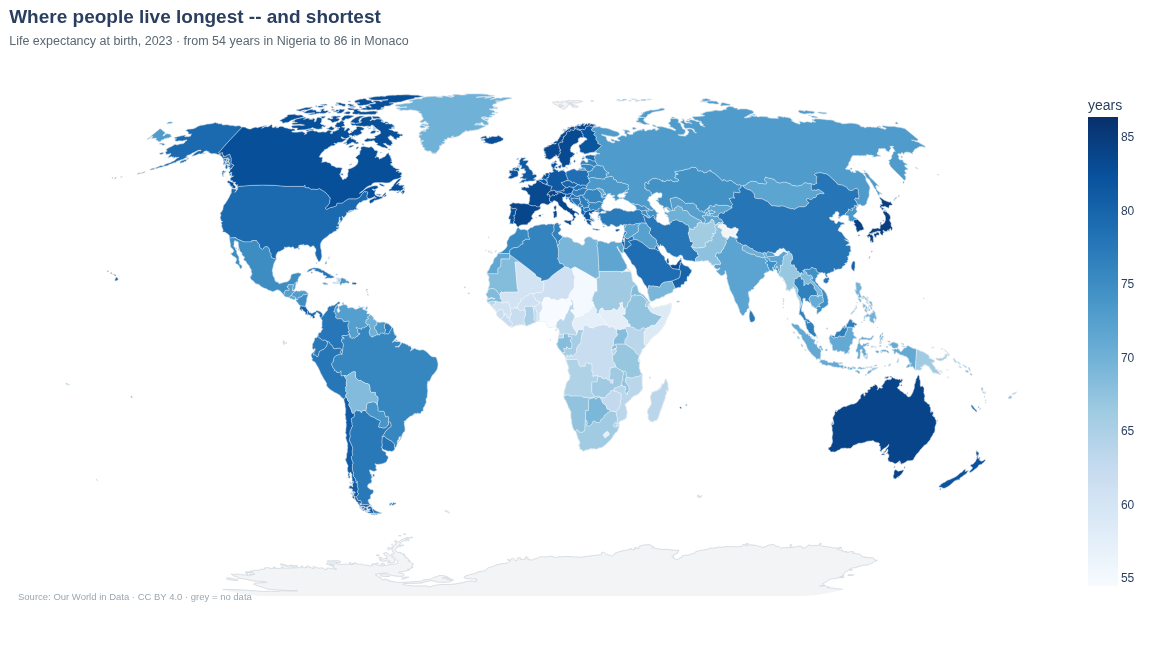

In [3]:
snap = latest_snapshot(panel, "life_expectancy", window=2)
top, low = snap.nlargest(1, "value").iloc[0], snap.nsmallest(1, "value").iloc[0]
display(snap.nlargest(5, "value")[["country", "value", "ref_year"]].round(1))
display(snap.nsmallest(5, "value")[["country", "value", "ref_year"]].round(1))

world_map(snap, "map_life_expectancy",
          title="Where people live longest -- and shortest",
          subtitle=(f"Life expectancy at birth, {int(snap['ref_year'].max())} · "
                    f"from {low['value']:.0f} years in {low['country']} "
                    f"to {top['value']:.0f} in {top['country']}"),
          unit="years", colorscale="Blues", range_min=52, range_max=86)

The extremes here are Monaco (86.4) and Nigeria (54.5) — a 32-year spread about where a child is born. Note the deliberate contrast with country_comparison.ipynb's ranking table: the table filtered out microstates and the map doesn't, which is why the map's top end reads Monaco and San Marino rather than Hong Kong and Japan. Both choices are defensible — the map colours *territory*, the table was ranking health outcomes *at scale* — but it's worth knowing which one you're looking at. The broad geography is identical either way: longest lives in East Asia and Western Europe, shortest in the Sahel and southern Africa.

## 2. Change since 1990

median country gain since 1990: +7.5 years · 3 countries lost ground: Jamaica, Lesotho, Palestine


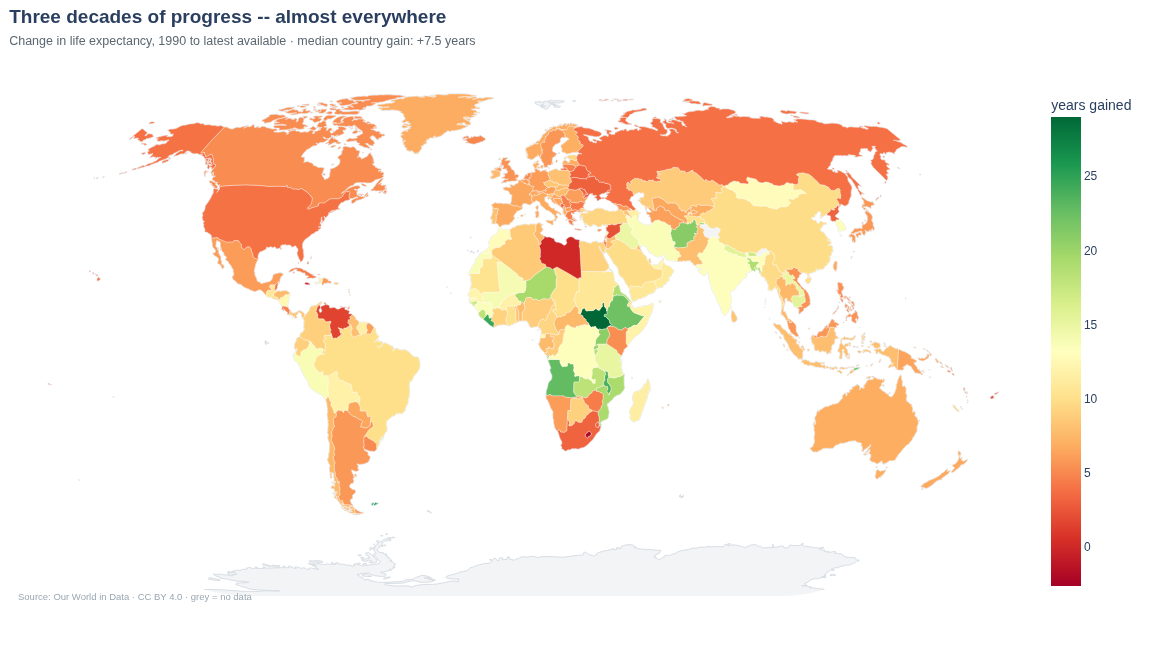

In [4]:
movers = endpoint_movers(panel, "life_expectancy", 1990, 2024)
iso = panel[["country", "iso3"]].dropna().drop_duplicates("country")
snap = (movers.merge(iso, on="country", how="inner")
        .rename(columns={"change": "value", "end_year": "ref_year"}))

median_gain = snap["value"].median()
decliners = snap[snap["value"] <= 0]
print(f"median country gain since 1990: +{median_gain:.1f} years · "
      f"{len(decliners)} countries lost ground: {', '.join(decliners['country'])}")

world_map(snap, "map_le_change",
          title="Three decades of progress -- almost everywhere",
          subtitle=(f"Change in life expectancy, 1990 to latest available · "
                    f"median country gain: +{median_gain:.1f} years"),
          unit="years gained", colorscale="RdYlGn", zmid=0)

Green almost everywhere: the median country gained **+7.5 years**, and only three lost ground — Jamaica (−0.2), Lesotho (−1.9), Palestine (−2.6). The pale zones carry the story: the southern-African HIV belt, the former USSR's post-1990 mortality crisis, and the conflict states of the 2010s. The United States (+3.9) is visibly paler than Canada or Western Europe — the rich-world outlier that keeps showing up in every view of this data.

One caveat baked into the diverging scale: countries ending in a COVID year (2021–22 for several late publishers) show their pandemic-era value, not their trend — part of every pale patch is 2020–21, not 1990–2020.

## 3. Child mortality today

27 countries above 50 per 1,000 · 23 of them in Africa · outside Africa: Kiribati, Haiti, Pakistan, Afghanistan


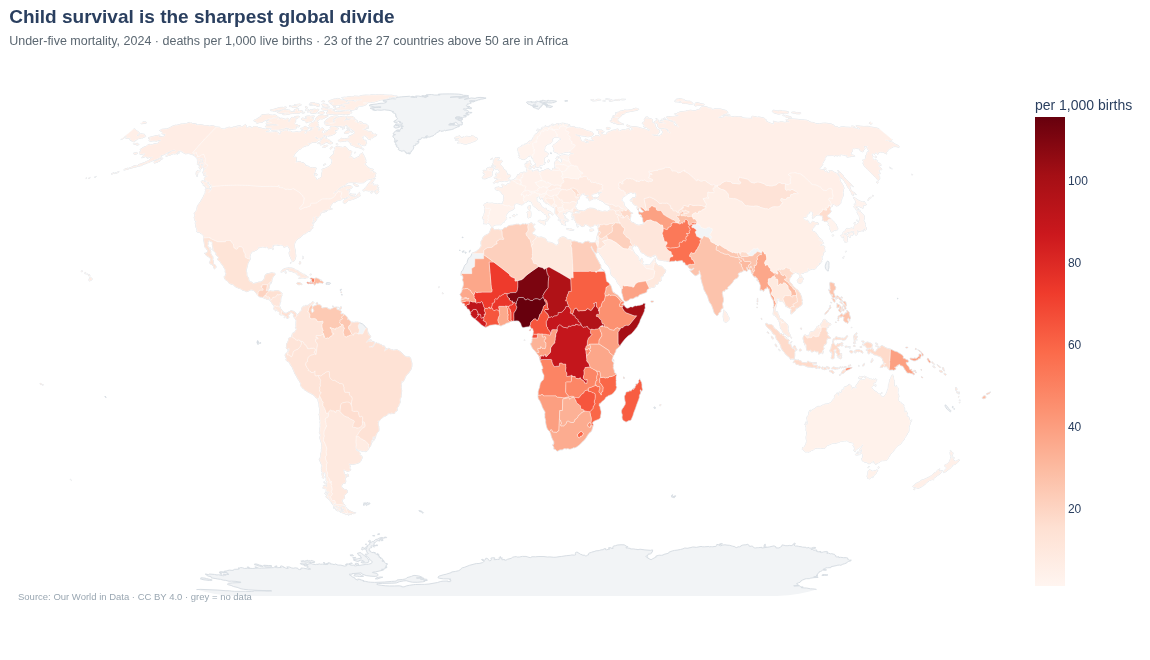

In [5]:
snap = latest_snapshot(panel, "child_mortality", window=2)
over50 = snap[snap["value"] > 50]
n_africa = len(over50[over50["region"] == "Africa"])
print(f"{len(over50)} countries above 50 per 1,000 · {n_africa} of them in Africa · "
      f"outside Africa: {', '.join(over50[over50['region'] != 'Africa']['country'])}")

world_map(snap, "map_child_mortality",
          title="Child survival is the sharpest global divide",
          subtitle=(f"Under-five mortality, {int(snap['ref_year'].max())} · deaths per 1,000 live births · "
                    f"{n_africa} of the {len(over50)} countries above 50 are in Africa"),
          unit="per 1,000 births", colorscale="Reds",
          range_min=0, range_max=snap["value"].quantile(0.98), label_fmt=".0f")

The reds concentrate in one contiguous belt — Sahel through the Horn to equatorial Africa. **23 of the 27 countries above 50 per 1,000 are African**; the four exceptions (Afghanistan, Pakistan, Haiti, Kiribati) sharpen the point rather than weaken it — each is the conflict or isolation case of its own region. The colour scale is capped at the 98th percentile so the worst handful don't wash out the rest — which also means the darkest reds are *at least* as bad as they look.

## 4. Air pollution (2019)

highest national rate: Tajikistan at 159 per 100,000


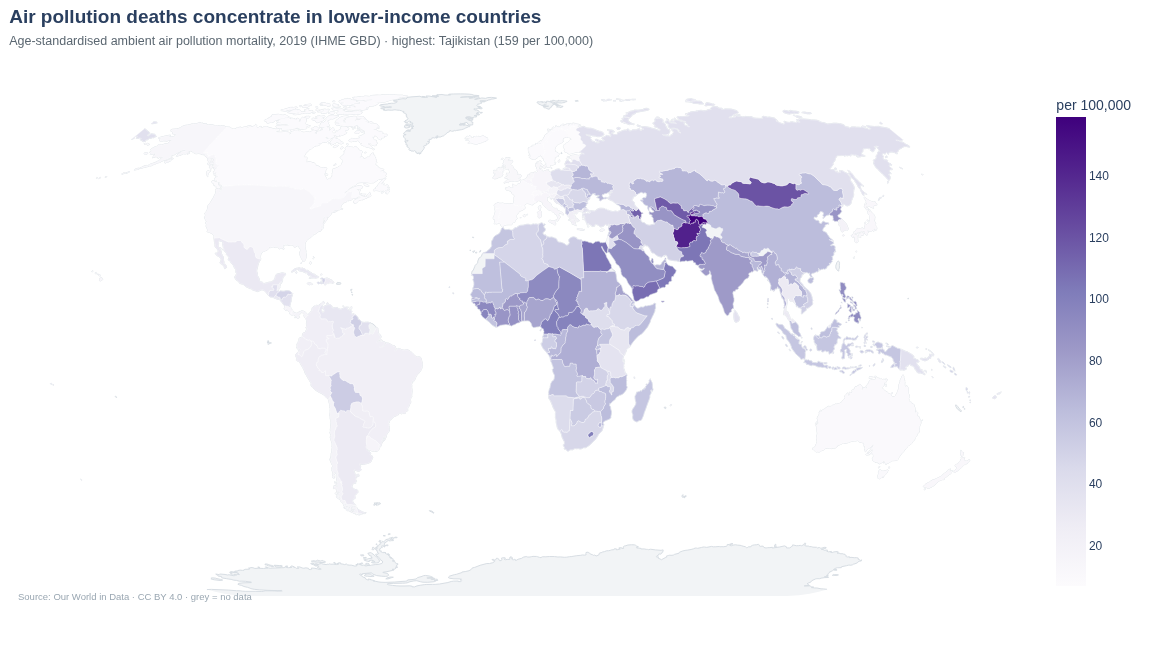

In [6]:
snap = latest_snapshot(panel, "air_pollution_deaths", window=5)
highest = snap.nlargest(1, "value").iloc[0]
print(f"highest national rate: {highest['country']} at {highest['value']:.0f} per 100,000")

world_map(snap, "map_air_pollution",
          title="Air pollution deaths concentrate in lower-income countries",
          subtitle=(f"Age-standardised ambient air pollution mortality, {int(snap['ref_year'].max())} (IHME GBD) · "
                    f"highest: {highest['country']} ({highest['value']:.0f} per 100,000)"),
          unit="per 100,000", colorscale="Purples", label_fmt=".0f")

The purples deepen across Central and South Asia, the Middle East and the Sahel; **Tajikistan** carries the highest age-standardised rate on earth (~159 per 100,000), with Nepal, India and a cluster of Central Asian and African states behind it. What this map is *not*: more than one year (IHME's GBD 2019 estimates), more than a model (exposure models + concentration-response functions, not death certificates), or more than a national average — within-country variation in India or Indonesia is enormous and invisible at this resolution.

## Reading maps without being fooled by them

- **Colour scales do the arguing.** Four maps, four scales, each chosen for its indicator; a single shared scale would make three of the four unreadable. Any cross-map comparison of colour intensity ("this country is redder on the child-mortality map than the pollution one") is meaningless.
- **Small states are invisible at world scale.** Hong Kong and Singapore — the top of the longevity table — are dots; the Sahel's crises are drawn large. Choropleths weight *area*, not people.
- **Grey is information.** No 2019 pollution estimate for a handful of states, no recent survey for a few others; a map that pretended the world was complete would lie by omission.
- **National averages hide within-country gaps** — the same ecological caveat as every other chart in this project, only spatial. US county-level or Indian district-level gaps are bigger than most between-country ones.

## Recap — and where everything lives

Four maps, four framings of one divide: the geography of health outcomes tracks the geography of income, conflict and health-system reach almost perfectly — with the southern-Sahel belt and the former USSR as the two great exceptions to the global improvement story.

That closes the analysis. The write-up with every figure is in **[docs/findings.md](../docs/findings.md)**, everything these notebooks can and cannot support is in **[docs/limitations.md](../docs/limitations.md)**, and the column-by-column description of the panel (units, quirks and all) is in **[docs/data_dictionary.md](../docs/data_dictionary.md)**.